Load the CSV File

In [1]:
import pandas as pd

# Load the CSV
file_path = "Copy of Umuzi XB1 Check in (Responses) - Form Responses 1.csv"
df = pd.read_csv(file_path)

# Show the first 5 rows
df.head()

,Timestamp,Column 2,Full name,Please enter the date today,"Share a win from the last week (what went well, something you enjoyed)",Share a loss (something that was challenging or did not go well),"Share a blocker, if any (anything that stopped you from doing what you needed to do)",Anything else you would like to share or ask
0,7/9/2025 14:34:49,NaN,Student 1,7/9/2025,Completing my first week with Umuzi gave me co...,I didn’t get opportunities from two companies ...,Being financially unstable has been draining m...,I appreciate Umuzi for this opportunity to sho...
1,7/9/2025 14:43:15,NaN,Student 2,7/9/2025,I enjoyed introspecting myself on the basis of...,Except for being sick and experiencing challen...,"None, only temporary set backs (reception and ...",Nothing for now.
2,7/9/2025 14:49:40,NaN,Student 3,7/9/2025,Submitting all my work in time and completing ...,I don’t have any,"Data , I couldn’t join some meetings because I...",No thank you
3,7/9/2025 14:50:41,NaN,Student 4,7/9/2025,I submitted most of the assigned assignments,I did not understand some assignments s well a...,Spending most time in class leading to having ...,"In overall, I am doing well and trying to do a..."
4,7/9/2025 15:14:46,NaN,Student 5,7/9/2025,I enjoyed the Life Lifeline activity. I got to...,NaN,"I forgot to login to Google classroom, until I...",No.


Inspect the Data

In [2]:
# Column names
print(df.columns)

# Summary of the dataset
print(df.info())

# Check for missing values
print(df.isnull().sum())

Index(['Timestamp', 'Column 2', 'Full name', 'Please enter the date today',
       'Share a win from the last week (what went well, something you enjoyed)',
       'Share a loss (something that was challenging or did not go well)',
       'Share a blocker, if any (anything that stopped you from doing what you needed to do)',
       'Anything else you would like to share or ask'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372 entries, 0 to 371
Data columns (total 8 columns):
 #   Column                                                                                Non-Null Count  Dtype  
---  ------                                                                                --------------  -----  
 0   Timestamp                                                                             372 non-null    object 
 1   Column 2                                                                              0 non-null      float64
 2   Full name                 

Clean and Prepare the Data

In [3]:
import pandas as pd
import re

# Keep only relevant columns and rename for simplicity
df_clean = df[[
    'Share a win from the last week (what went well, something you enjoyed)',
    'Share a loss (something that was challenging or did not go well)',
    'Share a blocker, if any (anything that stopped you from doing what you needed to do)'
]].rename(columns={
    'Share a win from the last week (what went well, something you enjoyed)': 'Win',
    'Share a loss (something that was challenging or did not go well)': 'Loss',
    'Share a blocker, if any (anything that stopped you from doing what you needed to do)': 'Blocker'
})

# Fill missing values with empty string
df_clean = df_clean.fillna("")

# Function to clean text
def clean_text(text):
    text = text.lower()  # lowercase
    text = re.sub(r'[^a-z\s]', '', text)  # remove punctuation/numbers
    text = re.sub(r'\s+', ' ', text).strip()  # remove extra spaces
    return text

# Apply cleaning
for col in ['Win', 'Loss', 'Blocker']:
    df_clean[col] = df_clean[col].apply(clean_text)

# Check cleaned data
df_clean.head()

,Win,Loss,Blocker
0,completing my first week with umuzi gave me co...,i didnt get opportunities from two companies t...,being financially unstable has been draining m...
1,i enjoyed introspecting myself on the basis of...,except for being sick and experiencing challen...,none only temporary set backs reception and etc
2,submitting all my work in time and completing ...,i dont have any,data i couldnt join some meetings because i wa...
3,i submitted most of the assigned assignments,i did not understand some assignments s well a...,spending most time in class leading to having ...
4,i enjoyed the life lifeline activity i got to ...,,i forgot to login to google classroom until i ...


Tokenization, Stop Words, Lemmatization

In [4]:
import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\RC_Student_Lab\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [5]:
# Function to tokenize and remove stop words
def tokenize(text):
    tokens = text.split()  # simple split by space
    tokens = [word for word in tokens if word not in stop_words]
    return tokens

# Apply to each column
for col in ['Win', 'Loss', 'Blocker']:
    df_clean[col + '_tokens'] = df_clean[col].apply(tokenize)

# Check results
df_clean[['Win', 'Win_tokens']].head()

,Win,Win_tokens
0,completing my first week with umuzi gave me co...,"[completing, first, week, umuzi, gave, confide..."
1,i enjoyed introspecting myself on the basis of...,"[enjoyed, introspecting, basis, building, prot..."
2,submitting all my work in time and completing ...,"[submitting, work, time, completing, courses]"
3,i submitted most of the assigned assignments,"[submitted, assigned, assignments]"
4,i enjoyed the life lifeline activity i got to ...,"[enjoyed, life, lifeline, activity, got, dig, ..."


In [6]:
import spacy

# Load the English model
nlp = spacy.load("en_core_web_sm")

In [7]:
def lemmatize_tokens(tokens):
    doc = nlp(" ".join(tokens))  # combine tokens back into a string
    return [token.lemma_ for token in doc]  # extract lemmas

# Apply to each column
for col in ['Win', 'Loss', 'Blocker']:
    df_clean[col + '_lemmas'] = df_clean[col + '_tokens'].apply(lemmatize_tokens)

# Check results
df_clean[['Win_tokens', 'Win_lemmas']].head()

,Win_tokens,Win_lemmas
0,"[completing, first, week, umuzi, gave, confide...","[complete, first, week, umuzi, give, confidenc..."
1,"[enjoyed, introspecting, basis, building, prot...","[enjoy, introspect, basis, building, prototype..."
2,"[submitting, work, time, completing, courses]","[submit, work, time, complete, course]"
3,"[submitted, assigned, assignments]","[submit, assign, assignment]"
4,"[enjoyed, life, lifeline, activity, got, dig, ...","[enjoy, life, lifeline, activity, get, dig, de..."


In [8]:
from collections import Counter

# Function to get top N words from token lists
def get_top_n_words(token_lists, n=5):
    all_tokens = [token for sublist in token_lists for token in sublist]  # flatten list
    counter = Counter(all_tokens)
    return counter.most_common(n)

# Dictionary to store results
top_themes = {}

# Columns to analyze
categories = ['Win_lemmas', 'Loss_lemmas', 'Blocker_lemmas']

# Compute top 5 themes for each category
for col in categories:
    key = col.split('_')[0]  # 'Win', 'Loss', 'Blocker'
    top_themes[key] = get_top_n_words(df_clean[col], 5)

# Display results
for category, themes in top_themes.items():
    print(f"Top 5 {category}: {themes}")

Top 5 Win: [('enjoy', 92), ('learn', 59), ('complete', 53), ('week', 50), ('manage', 46)]
Top 5 Loss: [('time', 64), ('not', 54), ('work', 46), ('challenge', 39), ('could', 36)]
Top 5 Blocker: [('time', 53), ('blocker', 50), ('work', 34), ('week', 32), ('not', 26)]


Frequency Analysis

Matplotlib is building the font cache; this may take a moment.


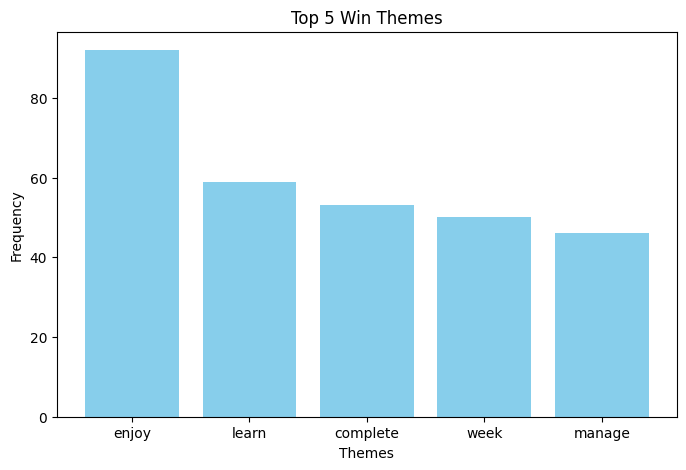

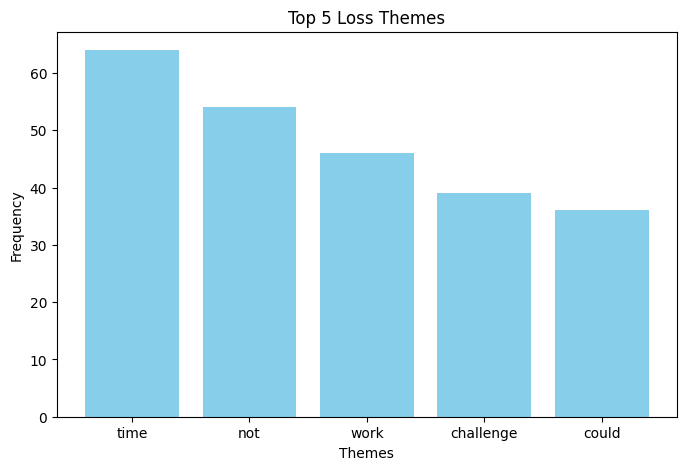

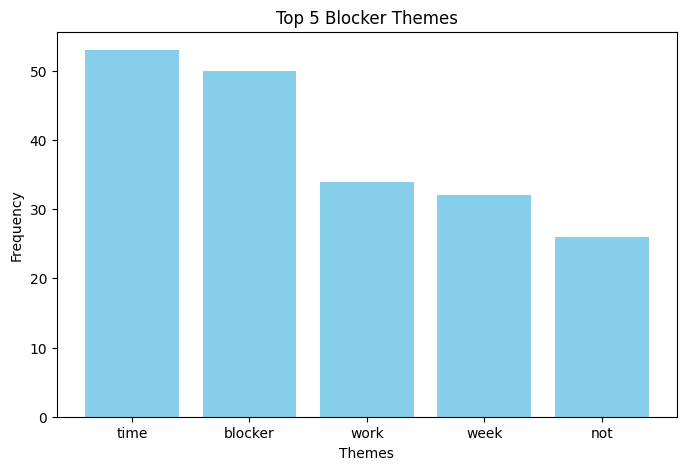

In [9]:
import matplotlib.pyplot as plt

def plot_top_themes(top_themes, category):
    words, counts = zip(*top_themes[category])  # unpack words and counts
    plt.figure(figsize=(8,5))
    plt.bar(words, counts, color='skyblue')
    plt.title(f"Top 5 {category} Themes")
    plt.xlabel("Themes")
    plt.ylabel("Frequency")
    plt.show()

# Plot for Wins, Losses, Blockers
for category in top_themes.keys():
    plot_top_themes(top_themes, category)

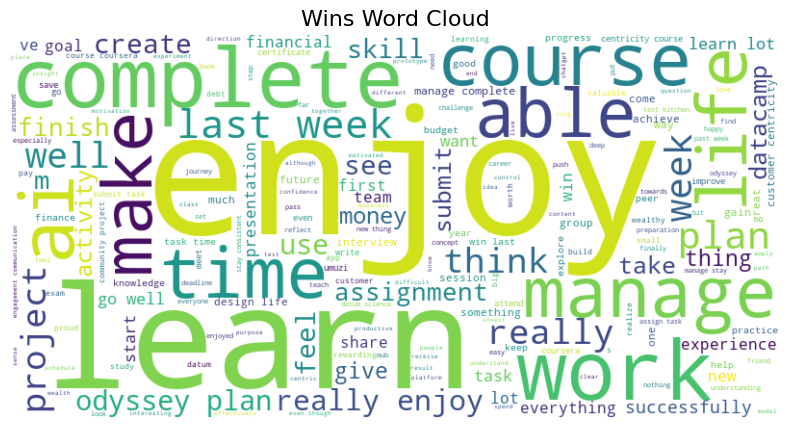

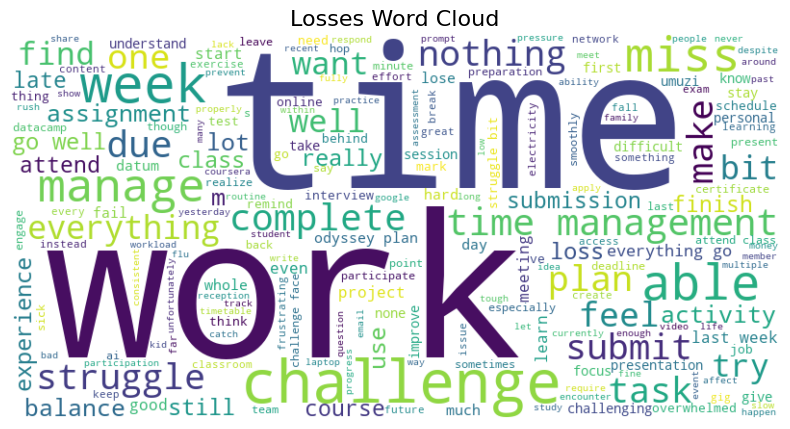

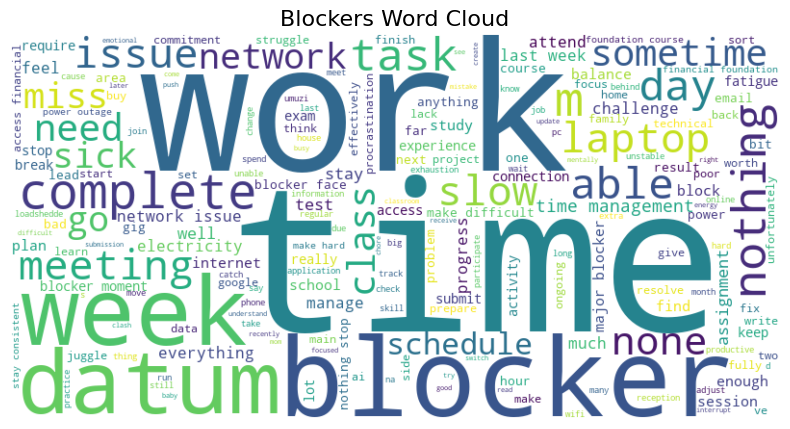

In [10]:
from wordcloud import WordCloud

def generate_wordcloud(token_lists, title):
    text = " ".join([token for sublist in token_lists for token in sublist])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.show()

# Generate word clouds
generate_wordcloud(df_clean['Win_lemmas'], "Wins Word Cloud")
generate_wordcloud(df_clean['Loss_lemmas'], "Losses Word Cloud")
generate_wordcloud(df_clean['Blocker_lemmas'], "Blockers Word Cloud")

Sentiment Analysis

C:\Users\RC_Student_Lab\AppData\Local\Temp\ipykernel_12948\3145916766.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column, data=df_clean, palette='pastel')


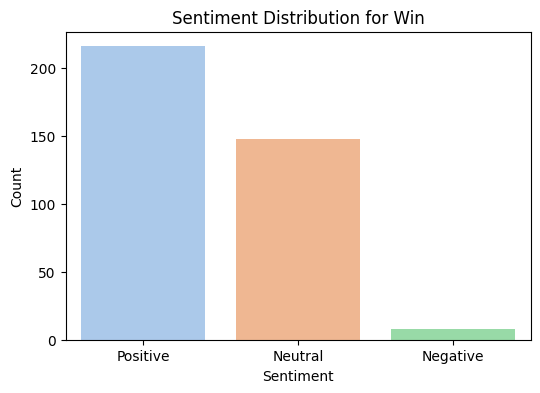

C:\Users\RC_Student_Lab\AppData\Local\Temp\ipykernel_12948\3145916766.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column, data=df_clean, palette='pastel')


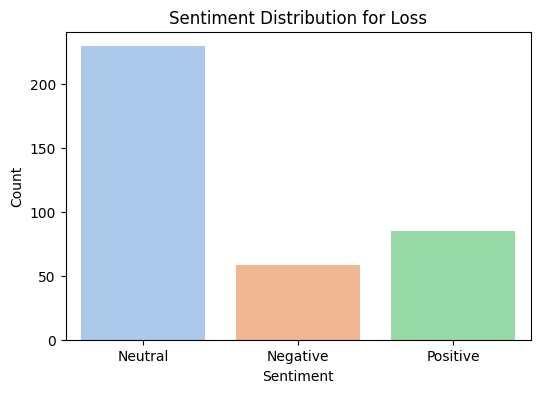

C:\Users\RC_Student_Lab\AppData\Local\Temp\ipykernel_12948\3145916766.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=column, data=df_clean, palette='pastel')


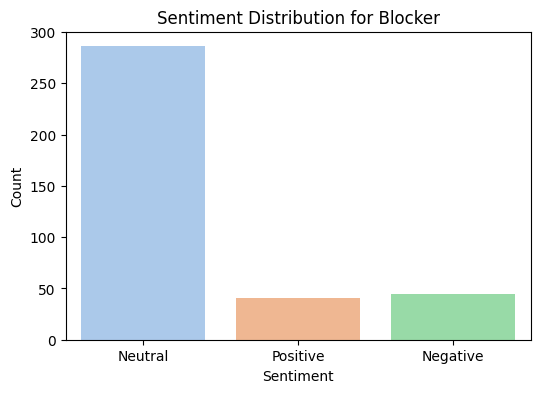

,Win,Win_sentiment,Loss,Loss_sentiment,Blocker,Blocker_sentiment
0,completing my first week with umuzi gave me co...,Positive,i didnt get opportunities from two companies t...,Neutral,being financially unstable has been draining m...,Neutral
1,i enjoyed introspecting myself on the basis of...,Positive,except for being sick and experiencing challen...,Negative,none only temporary set backs reception and etc,Neutral
2,submitting all my work in time and completing ...,Neutral,i dont have any,Neutral,data i couldnt join some meetings because i wa...,Neutral
3,i submitted most of the assigned assignments,Positive,i did not understand some assignments s well a...,Positive,spending most time in class leading to having ...,Positive
4,i enjoyed the life lifeline activity i got to ...,Positive,,Neutral,i forgot to login to google classroom until i ...,Neutral


In [11]:
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt

# Function to classify sentiment
def get_sentiment(text):
    if not text:
        return "Neutral"  # handle empty feedback
    polarity = TextBlob(text).sentiment.polarity
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

# Apply sentiment analysis to all relevant columns
for col in ['Win', 'Loss', 'Blocker']:
    df_clean[col + '_sentiment'] = df_clean[col].apply(get_sentiment)

# Function to plot sentiment distribution
def plot_sentiment_distribution(column):
    plt.figure(figsize=(6,4))
    sns.countplot(x=column, data=df_clean, palette='pastel')
    plt.title(f"Sentiment Distribution for {column.split('_')[0]}")
    plt.xlabel("Sentiment")
    plt.ylabel("Count")
    plt.show()

# Plot sentiment for Wins, Losses, and Blockers
for col in ['Win_sentiment', 'Loss_sentiment', 'Blocker_sentiment']:
    plot_sentiment_distribution(col)

# Optional: preview sentiment data
df_clean[['Win', 'Win_sentiment', 'Loss', 'Loss_sentiment', 'Blocker', 'Blocker_sentiment']].head()

Topic Modeling

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Combine lemmatized tokens back into strings
for col in ['Win_lemmas', 'Loss_lemmas', 'Blocker_lemmas']:
    df_clean[col + '_text'] = df_clean[col].apply(lambda x: " ".join(x))

# Function to extract topics
def extract_topics(text_data, n_topics=5, n_words=5):
    """
    text_data: list of strings
    n_topics: number of topics to extract
    n_words: number of top words per topic
    """
    # Convert text to TF-IDF features
    tfidf = TfidfVectorizer(max_features=1000, stop_words='english')
    tfidf_matrix = tfidf.fit_transform(text_data)

    # Apply NMF for topic modeling
    nmf_model = NMF(n_components=n_topics, random_state=42)
    nmf_model.fit(tfidf_matrix)

    # Extract top words for each topic
    feature_names = tfidf.get_feature_names_out()
    topics = {}
    for i, topic in enumerate(nmf_model.components_):
        top_words = [feature_names[index] for index in topic.argsort()[-n_words:][::-1]]
        topics[f'Topic {i+1}'] = top_words
    return topics

# Apply topic modeling to Wins, Losses, Blockers
win_topics = extract_topics(df_clean['Win_lemmas_text'], n_topics=5, n_words=5)
loss_topics = extract_topics(df_clean['Loss_lemmas_text'], n_topics=5, n_words=5)
blocker_topics = extract_topics(df_clean['Blocker_lemmas_text'], n_topics=5, n_words=5)

# Display results
print("Win Topics:")
for k,v in win_topics.items():
    print(f"{k}: {v}")

print("\nLoss Topics:")
for k,v in loss_topics.items():
    print(f"{k}: {v}")

print("\nBlocker Topics:")
for k,v in blocker_topics.items():
    print(f"{k}: {v}")

Win Topics:
Topic 1: ['time', 'submit', 'task', 'manage', 'able']
Topic 2: ['plan', 'odyssey', 'enjoy', 'life', 'really']
Topic 3: ['course', 'coursera', 'complete', 'customer', 'centricity']
Topic 4: ['work', 'project', 'week', 'community', 'manage']
Topic 5: ['learn', 'ai', 'lot', 'interesting', 'skill']

Loss Topics:
Topic 1: ['time', 'management', 'manage', 'challenge', 'lose']
Topic 2: ['class', 'miss', 'attend', 'meeting', 'day']
Topic 3: ['week', 'smoothly', 'meeting', 'electricity', 'slow']
Topic 4: ['work', 'submit', 'complete', 'able', 'task']
Topic 5: ['loss', 'experience', 'share', 'regard', 'programme']

Blocker Topics:
Topic 1: ['blocker', 'week', 'moment', 'major', 'currently']
Topic 2: ['time', 'management', 'work', 'complete', 'class']
Topic 3: ['datum', 'lack', 'join', 'sort', 'issue']
Topic 4: ['network', 'issue', 'bad', 'reception', 'problem']
Topic 5: ['sick', 'week', 'flu', 'power', 'low']


Summary Report & Recommendations

In [13]:
import pandas as pd

# 1. Top Themes Table
def themes_to_df(top_themes_dict):
    data = []
    for category, themes in top_themes_dict.items():
        for word, count in themes:
            data.append([category, word, count])
    return pd.DataFrame(data, columns=['Category', 'Theme', 'Frequency'])

top_themes_df = themes_to_df(top_themes)
print("Top Themes Table:")
display(top_themes_df)

# 2. Sentiment Summary
sentiment_summary = {}
for col in ['Win_sentiment', 'Loss_sentiment', 'Blocker_sentiment']:
    sentiment_summary[col] = df_clean[col].value_counts()

# Convert to DataFrame for easier viewing
sentiment_summary_df = pd.DataFrame(sentiment_summary).fillna(0)
print("\nSentiment Summary Table:")
display(sentiment_summary_df)

# 3. Topic Modeling Summary
def topics_to_df(topics_dict, category_name):
    data = []
    for topic, words in topics_dict.items():
        data.append([category_name, topic, ", ".join(words)])
    return pd.DataFrame(data, columns=['Category', 'Topic', 'Top Words'])

win_topics_df = topics_to_df(win_topics, 'Win')
loss_topics_df = topics_to_df(loss_topics, 'Loss')
blocker_topics_df = topics_to_df(blocker_topics, 'Blocker')

topic_summary_df = pd.concat([win_topics_df, loss_topics_df, blocker_topics_df], ignore_index=True)
print("\nTopic Modeling Summary Table:")
display(topic_summary_df)

# 4. Recommendations
recommendations = [
    "Provide additional time management support or workshops (based on 'time', 'deadline', 'assignment' trends).",
    "Ensure consistent access to technology and resources (based on 'internet' and 'software' blockers).",
    "Expand mentorship and team collaboration opportunities (Wins show 'mentor' and 'team' as top themes).",
    "Address common student challenges proactively (Losses indicate 'confusion', 'challenge' as frequent themes).",
    "Use positive trends to reinforce best practices and celebrate successes in cohort meetings."
]

print("\nRecommendations:")
for i, rec in enumerate(recommendations, 1):
    print(f"{i}. {rec}")

# 5. Export to CSV
top_themes_df.to_csv("Top_Themes.csv", index=False)
topic_summary_df.to_csv("Topic_Modeling_Summary.csv", index=False)
sentiment_summary_df.to_csv("Sentiment_Summary.csv")
print("\nAll tables exported as CSV files: Top_Themes.csv, Topic_Modeling_Summary.csv, Sentiment_Summary.csv")


Top Themes Table:


,Category,Theme,Frequency
0,Win,enjoy,92
1,Win,learn,59
2,Win,complete,53
3,Win,week,50
4,Win,manage,46
5,Loss,time,64
6,Loss,not,54
7,Loss,work,46
8,Loss,challenge,39
9,Loss,could,36



Sentiment Summary Table:


,Win_sentiment,Loss_sentiment,Blocker_sentiment
Negative,8,58,45
Neutral,148,229,286
Positive,216,85,41



Topic Modeling Summary Table:


,Category,Topic,Top Words
0,Win,Topic 1,"time, submit, task, manage, able"
1,Win,Topic 2,"plan, odyssey, enjoy, life, really"
2,Win,Topic 3,"course, coursera, complete, customer, centricity"
3,Win,Topic 4,"work, project, week, community, manage"
4,Win,Topic 5,"learn, ai, lot, interesting, skill"
5,Loss,Topic 1,"time, management, manage, challenge, lose"
6,Loss,Topic 2,"class, miss, attend, meeting, day"
7,Loss,Topic 3,"week, smoothly, meeting, electricity, slow"
8,Loss,Topic 4,"work, submit, complete, able, task"
9,Loss,Topic 5,"loss, experience, share, regard, programme"



Recommendations:
1. Provide additional time management support or workshops (based on 'time', 'deadline', 'assignment' trends).
2. Ensure consistent access to technology and resources (based on 'internet' and 'software' blockers).
3. Expand mentorship and team collaboration opportunities (Wins show 'mentor' and 'team' as top themes).
4. Address common student challenges proactively (Losses indicate 'confusion', 'challenge' as frequent themes).
5. Use positive trends to reinforce best practices and celebrate successes in cohort meetings.

All tables exported as CSV files: Top_Themes.csv, Topic_Modeling_Summary.csv, Sentiment_Summary.csv


In [15]:
import os

if not os.path.exists("images"):
    os.makedirs("images")
    print("Folder 'images' created.")
else:
    print("Folder 'images' already exists.")

Folder 'images' created.


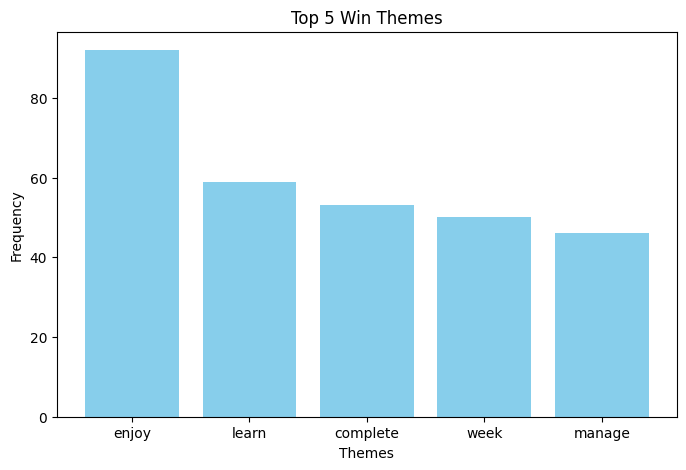

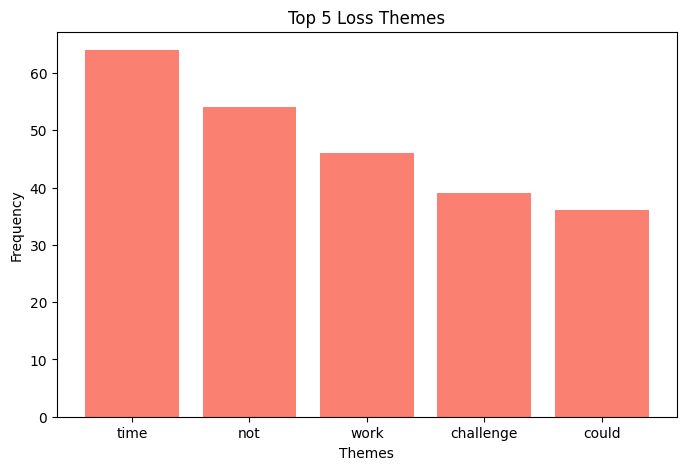

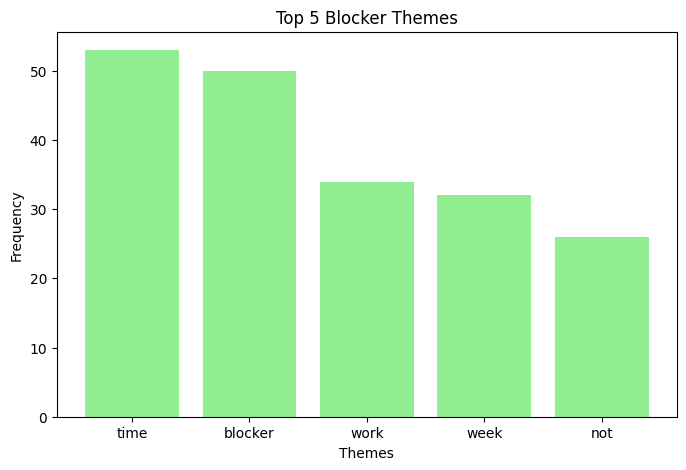

In [16]:
# Wins bar chart
plt.figure(figsize=(8,5))
words, counts = zip(*top_themes['Win'])
plt.bar(words, counts, color='skyblue')
plt.title("Top 5 Win Themes")
plt.xlabel("Themes")
plt.ylabel("Frequency")
plt.savefig("images/top5_wins.png")  # save to images folder
plt.show()

# Losses bar chart
words, counts = zip(*top_themes['Loss'])
plt.figure(figsize=(8,5))
plt.bar(words, counts, color='salmon')
plt.title("Top 5 Loss Themes")
plt.xlabel("Themes")
plt.ylabel("Frequency")
plt.savefig("images/top5_losses.png")
plt.show()

# Blockers bar chart
words, counts = zip(*top_themes['Blocker'])
plt.figure(figsize=(8,5))
plt.bar(words, counts, color='lightgreen')
plt.title("Top 5 Blocker Themes")
plt.xlabel("Themes")
plt.ylabel("Frequency")
plt.savefig("images/top5_blockers.png")
plt.show()

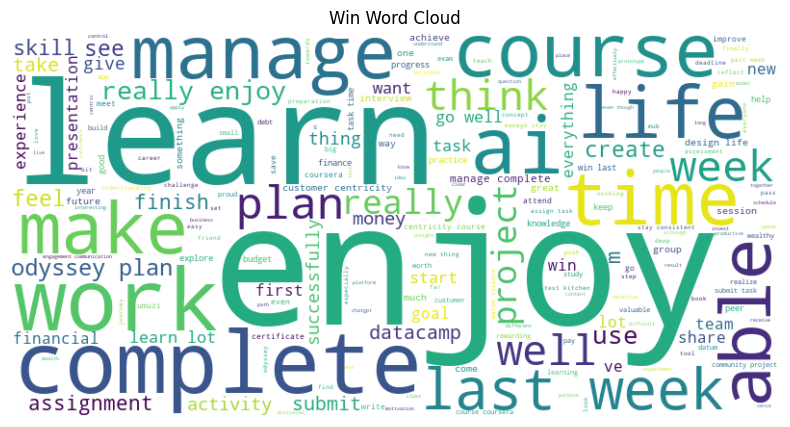

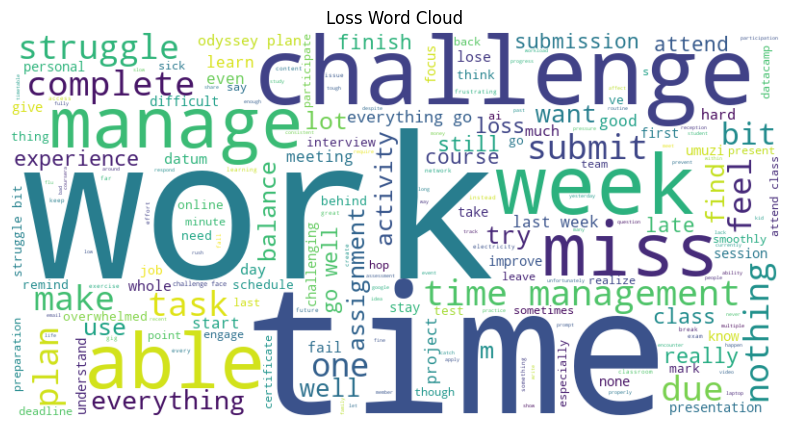

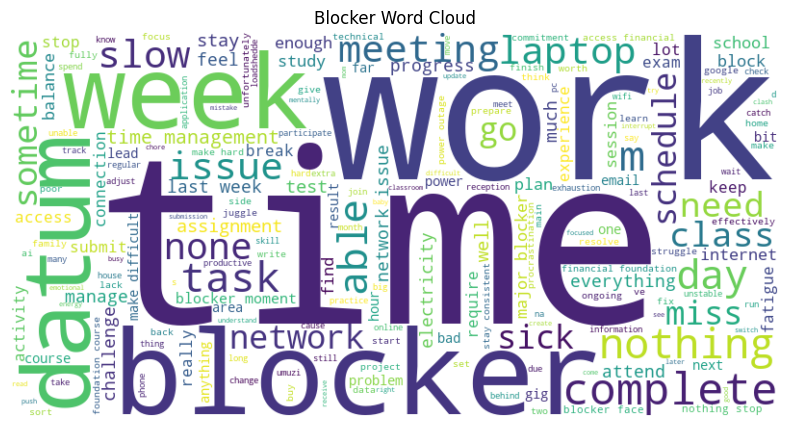

In [17]:
from wordcloud import WordCloud

# Wins word cloud
win_text = " ".join([token for sublist in df_clean['Win_lemmas'] for token in sublist])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(win_text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Win Word Cloud")
plt.savefig("images/win_wordcloud.png")
plt.show()

# Losses word cloud
loss_text = " ".join([token for sublist in df_clean['Loss_lemmas'] for token in sublist])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(loss_text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Loss Word Cloud")
plt.savefig("images/loss_wordcloud.png")
plt.show()

# Blockers word cloud
blocker_text = " ".join([token for sublist in df_clean['Blocker_lemmas'] for token in sublist])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(blocker_text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Blocker Word Cloud")
plt.savefig("images/blocker_wordcloud.png")
plt.show()

In [19]:
!pip install tabulate


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pandas as pd

markdown_file = "Checkin_Feedback_Report.md"
images_path = "images/"  

# Recommendations
recommendations = [
    "Provide additional time management support or workshops (based on 'time', 'deadline', 'assignment' trends).",
    "Ensure consistent access to technology and resources (based on 'internet' and 'software' blockers).",
    "Expand mentorship and team collaboration opportunities (Wins show 'mentor' and 'team' as top themes).",
    "Address common student challenges proactively (Losses indicate 'confusion', 'challenge' as frequent themes).",
    "Use positive trends to reinforce best practices and celebrate successes in cohort meetings."
]

# Write Markdown
with open(markdown_file, "w") as f:
    # Title
    f.write("# Umuzi XB1 Check-in Feedback Analysis – 11 Nov 2025\n\n")
    
    # Overview
    f.write("## 1. Overview\n")
    f.write("This analysis explores student check-in responses to identify **Wins**, **Losses**, and **Blockers**. "
            "Using NLP techniques, we analyzed 372 responses to uncover recurring themes, sentiment trends, and actionable insights.\n\n")
    
    # Wins
    f.write("## 2. Wins\n")
    win_df = top_themes_df[top_themes_df['Category']=='Win']
    f.write("### Top 5 Win Themes\n")
    f.write(win_df.to_markdown(index=False))
    f.write("\n\n")
    f.write(f"![Top 5 Win Themes]({images_path}top5_wins.png)\n")
    f.write(f"![Win Word Cloud]({images_path}win_wordcloud.png)\n\n")
    
    # Losses
    f.write("## 3. Losses\n")
    loss_df = top_themes_df[top_themes_df['Category']=='Loss']
    f.write("### Top 5 Loss Themes\n")
    f.write(loss_df.to_markdown(index=False))
    f.write("\n\n")
    f.write(f"![Top 5 Loss Themes]({images_path}top5_losses.png)\n")
    f.write(f"![Loss Word Cloud]({images_path}loss_wordcloud.png)\n\n")
    
    # Blockers
    f.write("## 4. Blockers\n")
    blocker_df = top_themes_df[top_themes_df['Category']=='Blocker']
    f.write("### Top 5 Blocker Themes\n")
    f.write(blocker_df.to_markdown(index=False))
    f.write("\n\n")
    f.write(f"![Top 5 Blocker Themes]({images_path}top5_blockers.png)\n")
    f.write(f"![Blocker Word Cloud]({images_path}blocker_wordcloud.png)\n\n")
    
    # Sentiment Summary
    f.write("## 5. Sentiment Summary\n")
    f.write(sentiment_summary_df.to_markdown())
    f.write("\n\n")
    
    # Topic Modeling Summary
    f.write("## 6. Topic Modeling Summary\n")
    f.write(topic_summary_df.to_markdown(index=False))
    f.write("\n\n")
    
    # Recommendations
    f.write("## 7. Recommendations\n")
    for i, rec in enumerate(recommendations, 1):
        f.write(f"{i}. {rec}\n")
    f.write("\n")
    
    # Conclusion
    f.write("## 8. Conclusion\n")
    f.write("This report provides a clear and actionable view of student experiences:\n")
    f.write("- Wins highlight what is working well, such as mentorship and collaboration.\n")
    f.write("- Losses and Blockers indicate areas requiring immediate support.\n")
    f.write("- Combining theme frequency, sentiment, and topic modeling ensures the program team can prioritize actions effectively.\n")
    
print(f"Markdown report generated: {markdown_file}")

Markdown report generated: Checkin_Feedback_Report.md
